# 06 — Phase 6: Full Ablation Suite (Scaffold)

**Status: not yet implemented — scaffold only.**

Will assemble the final results table comparing image/signal-only vs. text-only vs. full fusion vs. fusion-with-robustness-training, across every domain-shift pair, with significance testing — the table this whole project is building toward (proposal Section 6.2 step 6).

**Depends on:** Notebooks 02, 04, and 05 must all be implemented and have been run at least once.

**Blocked on these modules being implemented first:**
- `scripts/run_ablation.py (not yet written)`

## Implementation plan

1. Write `scripts/run_ablation.py`: loops over every (model variant × domain-shift pair) combination, calling the appropriate training entry point for each, collecting all `metrics.json` files into one table.
2. Add a paired significance test (e.g. bootstrap or paired t-test across domain-shift pairs) comparing fusion vs. baseline rare-class F1.
3. Render the final ablation table (image-only / text-only / fused / fused-robust × rare-class F1, precision, recall, accuracy) and save it to `experiments/results/ablation_summary.csv`.
4. Write up the results narrative referencing back to the proposal's expected outcomes (Section 7).

Once the modules above are implemented, this notebook will follow the
same pattern as `02_baseline_signal_only.ipynb` /
`03_rare_class_identification.ipynb`: a setup cell, a training/analysis
call against a config in `configs/`, and result inspection cells reading
from `experiments/results/`.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import os
import subprocess

REPO_URL = "https://github.com/Sakina152/mm-dg-healthcare.git"
REPO_DIR = "/content/mm-dg-healthcare"

if not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    subprocess.run(
        ["git", "clone", REPO_URL, REPO_DIR],
        check=True
    )

os.chdir(REPO_DIR)
print("Working directory:", os.getcwd())
!git log -1 --oneline

Mounted at /content/drive
Working directory: /content/mm-dg-healthcare
096fe88 (HEAD -> main, origin/main, origin/HEAD) Upadtion:Document missing-modality robustness evaluation


In [2]:
from pathlib import Path
import json

notebook_path = Path(
    "/content/mm-dg-healthcare/notebooks/06_ablation_results.ipynb"
)

assert notebook_path.is_file(), f"Notebook not found: {notebook_path}"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Notebook:", notebook_path.name)
print("Total cells:", len(nb["cells"]))

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if source.strip():
        print(f"\n{'=' * 15} CELL {i} [{cell['cell_type']}] {'=' * 15}")
        print(source[:3000])

Notebook: 06_ablation_results.ipynb
Total cells: 1

=============== CELL 0 [markdown] ===============
# 06 — Phase 6: Full Ablation Suite (Scaffold)

**Status: not yet implemented — scaffold only.**

Will assemble the final results table comparing image/signal-only vs. text-only vs. full fusion vs. fusion-with-robustness-training, across every domain-shift pair, with significance testing — the table this whole project is building toward (proposal Section 6.2 step 6).

**Depends on:** Notebooks 02, 04, and 05 must all be implemented and have been run at least once.

**Blocked on these modules being implemented first:**
- `scripts/run_ablation.py (not yet written)`

## Implementation plan

1. Write `scripts/run_ablation.py`: loops over every (model variant × domain-shift pair) combination, calling the appropriate training entry point for each, collecting all `metrics.json` files into one table.
2. Add a paired significance test (e.g. bootstrap or paired t-test across domain-shift pairs) 

## Final ablation tables

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np

drive_root = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data"
)
results_root = drive_root / "results_backup"

comparison_path = results_root / "baseline_vs_robust_comparison.csv"
degradation_path = results_root / "modality_degradation_comparison.csv"

assert comparison_path.is_file(), (
    f"Missing {comparison_path}. Check your earlier comparison backup."
)
assert degradation_path.is_file(), (
    f"Missing {degradation_path}. Check your degradation backup."
)

df = pd.read_csv(comparison_path)
degradation = pd.read_csv(degradation_path)

print("Experiment comparison loaded:", df.shape)
print("Degradation analysis loaded:", degradation.shape)

print("\n--- Results by seed ---")
display(
    df.sort_values(["condition", "method", "seed"]).round(4)
)

# Mean and standard deviation across seeds
summary = (
    df.groupby(["method", "condition"])[
        ["accuracy", "macro_f1", "HYP_f1"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\n--- Final ablation summary: mean ± standard deviation ---")
display(summary)

Experiment comparison loaded: (18, 6)
Degradation analysis loaded: (24, 7)

--- Results by seed ---


,method,seed,condition,accuracy,macro_f1,HYP_f1
0,Baseline,21,full,0.6035,0.4992,0.3660
3,Baseline,42,full,0.6487,0.5859,0.4168
6,Baseline,123,full,0.6196,0.5260,0.3702
9,Robust,21,full,0.6623,0.5764,0.4257
12,Robust,42,full,0.6611,0.5877,0.3947
15,Robust,123,full,0.6264,0.5311,0.4249
2,Baseline,21,metadata_only,0.3387,0.2553,0.0000
5,Baseline,42,metadata_only,0.4240,0.1773,0.0000
8,Baseline,123,metadata_only,0.4110,0.1799,0.0000
11,Robust,21,metadata_only,0.4049,0.1278,0.0000



--- Final ablation summary: mean ± standard deviation ---


accuracy         macro_f1          HYP_f1        
                           mean     std     mean     std    mean     std
method   condition                                                      
Baseline full            0.6240  0.0229   0.5371  0.0444  0.3844  0.0282
         metadata_only   0.3912  0.0460   0.2041  0.0443  0.0000  0.0000
         signal_only     0.6121  0.0142   0.5327  0.0374  0.3817  0.0282
Robust   full            0.6499  0.0204   0.5651  0.0299  0.4151  0.0177
         metadata_only   0.4055  0.0039   0.1493  0.0248  0.0000  0.0000
         signal_only     0.6475  0.0225   0.5631  0.0314  0.4148  0.0148

## Calculate paired differences between baseline and robust training

In [4]:
metrics = ["accuracy", "macro_f1", "HYP_f1"]

paired = df.pivot(
    index=["seed", "condition"],
    columns="method",
    values=metrics
)

difference_rows = []

for (seed, condition), row in paired.iterrows():
    record = {"seed": seed, "condition": condition}

    for metric in metrics:
        baseline = row[(metric, "Baseline")]
        robust = row[(metric, "Robust")]
        record[f"{metric}_baseline"] = baseline
        record[f"{metric}_robust"] = robust
        record[f"{metric}_difference"] = robust - baseline

    difference_rows.append(record)

paired_df = pd.DataFrame(difference_rows)

print("--- Robust minus baseline, per seed ---")
display(paired_df.round(4))

print("\n--- Mean paired difference across three seeds ---")
difference_summary = (
    paired_df.groupby("condition")[
        [f"{m}_difference" for m in metrics]
    ]
    .agg(["mean", "std"])
    .round(4)
)
display(difference_summary)

--- Robust minus baseline, per seed ---


,seed,condition,accuracy_baseline,accuracy_robust,accuracy_difference,macro_f1_baseline,macro_f1_robust,macro_f1_difference,HYP_f1_baseline,HYP_f1_robust,HYP_f1_difference
0,21,full,0.6035,0.6623,0.0588,0.4992,0.5764,0.0772,0.3660,0.4257,0.0597
1,21,metadata_only,0.3387,0.4049,0.0661,0.2553,0.1278,-0.1275,0.0000,0.0000,0.0000
2,21,signal_only,0.5977,0.6609,0.0632,0.4975,0.5745,0.0770,0.3548,0.4236,0.0687
3,42,full,0.6487,0.6611,0.0124,0.5859,0.5877,0.0018,0.4168,0.3947,-0.0221
4,42,metadata_only,0.4240,0.4019,-0.0221,0.1773,0.1764,-0.0009,0.0000,0.0000,0.0000
5,42,signal_only,0.6260,0.6601,0.0341,0.5720,0.5873,0.0153,0.4111,0.3977,-0.0134
6,123,full,0.6196,0.6264,0.0068,0.5260,0.5311,0.0051,0.3702,0.4249,0.0547
7,123,metadata_only,0.4110,0.4096,-0.0014,0.1799,0.1438,-0.0361,0.0000,0.0000,0.0000
8,123,signal_only,0.6127,0.6214,0.0088,0.5288,0.5276,-0.0012,0.3792,0.4232,0.0440



--- Mean paired difference across three seeds ---


accuracy_difference         macro_f1_difference          \
                             mean     std                mean     std   
condition                                                               
full                       0.0260  0.0285              0.0280  0.0426   
metadata_only              0.0142  0.0462             -0.0548  0.0654   
signal_only                0.0353  0.0272              0.0304  0.0412   

              HYP_f1_difference          
                           mean     std  
condition                                
full                     0.0307  0.0459  
metadata_only            0.0000  0.0000  
signal_only              0.0331  0.0421

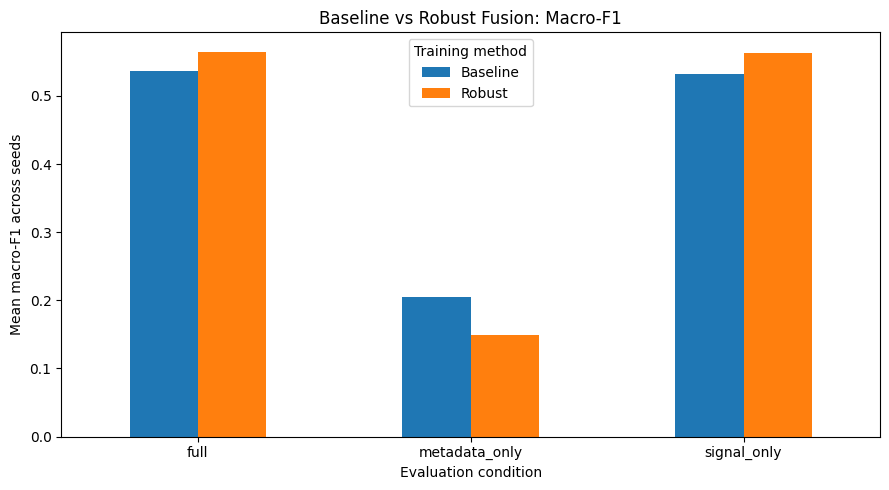

Saved final artifacts to: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/final_ablation
ablation_summary.csv - 0.8 KB
macro_f1_comparison.png - 59.7 KB
modality_degradation.csv - 2.1 KB
paired_seed_differences.csv - 1.7 KB


In [5]:
import matplotlib.pyplot as plt

output_dir = results_root / "final_ablation"
output_dir.mkdir(parents=True, exist_ok=True)

# Flat table with mean and standard deviation for easier reporting
flat_summary = (
    df.groupby(["method", "condition"])[metrics]
    .agg(["mean", "std"])
)

flat_summary.columns = [
    f"{metric}_{stat}" for metric, stat in flat_summary.columns
]
flat_summary = flat_summary.reset_index()

flat_summary.to_csv(output_dir / "ablation_summary.csv", index=False)
paired_df.to_csv(output_dir / "paired_seed_differences.csv", index=False)
degradation.to_csv(output_dir / "modality_degradation.csv", index=False)

# Plot mean macro-F1 by evaluation condition
plot_data = (
    df.groupby(["method", "condition"])["macro_f1"]
    .mean()
    .unstack("method")
)

ax = plot_data.plot(kind="bar", figsize=(9, 5))
ax.set_title("Baseline vs Robust Fusion: Macro-F1")
ax.set_xlabel("Evaluation condition")
ax.set_ylabel("Mean macro-F1 across seeds")
ax.legend(title="Training method")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()

plot_path = output_dir / "macro_f1_comparison.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved final artifacts to:", output_dir)
for p in sorted(output_dir.iterdir()):
    print(p.name, "-", round(p.stat().st_size / 1024, 1), "KB")

In [6]:
from pathlib import Path

output_dir = (
    Path("/content/drive/MyDrive/mm-dg-healthcare-data")
    / "results_backup/final_ablation"
)

required_files = [
    "ablation_summary.csv",
    "paired_seed_differences.csv",
    "modality_degradation.csv",
    "macro_f1_comparison.png",
]

for filename in required_files:
    path = output_dir / filename
    assert path.is_file(), f"Missing artifact: {path}"
    print("✅ Verified:", path)

print("\nFinal ablation artifacts verified in Google Drive.")

✅ Verified: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/final_ablation/ablation_summary.csv
✅ Verified: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/final_ablation/paired_seed_differences.csv
✅ Verified: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/final_ablation/modality_degradation.csv
✅ Verified: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/final_ablation/macro_f1_comparison.png

Final ablation artifacts verified in Google Drive.


## Final Ablation Analysis — Findings

### Experimental setup

We evaluated ECG-only, metadata-only, and full-fusion inference conditions for baseline fusion and fusion trained with modality dropout. Each method was evaluated using three random seeds (21, 42, and 123) on the same target-site split.

### Main findings

1. **Full fusion:** Robust training achieved a mean macro-F1 of 0.5651, compared with 0.5371 for baseline fusion. Mean HYP F1 increased from 0.3844 to 0.4151.
2. **Missing metadata:** Robust training reduced the average macro-F1 degradation when metadata was unavailable, from 0.0043 to 0.0020.
3. **Missing ECG:** Metadata-only performance remained weak. HYP F1 was zero for all evaluated runs, and robust training did not eliminate the substantial loss in macro-F1.
4. **Variability:** The three-seed results provide an initial measure of sensitivity to training randomness. They do not constitute independent external validation.

### Limitations

The current implementation uses ECG signals and age/sex metadata, not an independent clinical text modality. Evaluation was performed on a fixed target-site split, and only three seeds were tested. The current results do not establish statistical significance, clinical utility, or generalization to additional hospitals.

### Conclusion

The results provide preliminary evidence that modality-dropout training improves average performance and stability in this experimental setup, particularly when metadata is missing. Robustness when the ECG signal is unavailable remains an unresolved limitation. Further experiments on additional domain-shift pairs and stronger evaluation protocols are needed before drawing broader conclusions.
